# Marvel CPG V2 — Missing-Day Analysis and OOS Validation Experiments

**Data version:** V2  
**Purpose:** determine how Sell-out missing days, delivery semantics, inferred shelf refills, and promotion-driven demand should be handled before Module 2 model development.

This notebook contains two governed parts:

1. **Deep EDA:** Sell-out missingness, inventory transitions, inferred shelf refill, delivery-to-inventory reconciliation, and promotion-demand relationships.
2. **Controlled experiments:** artificial masking, candidate sales/inventory estimators, and the downstream effect of each missing-data strategy on seven-day OOS prediction.

Module 2 must simultaneously reach **Precision ≥ 0.75**, **Recall ≥ 0.70**, and **ROC-AUC ≥ 0.80**. March and April are development validation folds. May is a one-time validation gate after the strategy is selected. June is locked and is neither loaded into analytical panels nor evaluated here.

## Governance and interpretation rules

- A missing Sell-out account-day means **not reported**, never zero sales, zero inventory, or non-OOS.
- Observed values are never overwritten; estimates live in separate fields.
- `actual_delivery` is a logistics event until the reconciliation gate proves that it represents sellable inventory.
- An inferred shelf refill is derived from Sell-out inventory movement; it is not a confirmed delivery.
- Every learned value and every feature must use information available on or before prediction date `t`.
- Imputed future inventory never becomes OOS ground truth.
- Formal validation labels require seven fully observed future store-SKU days.

In [1]:
from __future__ import annotations

import json
import os
import warnings
from pathlib import Path

os.environ.setdefault("MPLCONFIGDIR", "/tmp/marvel-mpl-cache")
warnings.filterwarnings("ignore")

import lightgbm as lgb
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import Markdown, display
from scipy.stats import spearmanr
from sklearn.metrics import (
    average_precision_score,
    confusion_matrix,
    precision_recall_curve,
    precision_score,
    recall_score,
    roc_auc_score,
)

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 110, "axes.titleweight": "bold", "figure.figsize": (11, 5)})
pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 180)

RANDOM_SEED = 650
LOCKED_TEST_START = pd.Timestamp("2026-06-01")
EDA_END = pd.Timestamp("2026-04-30")
MAY_GATE_START = pd.Timestamp("2026-05-01")
MAY_GATE_END = pd.Timestamp("2026-05-24")
MIN_PRECISION, MIN_RECALL, MIN_AUC = 0.75, 0.70, 0.80

repo_candidates = [Path.cwd(), *Path.cwd().parents]
REPO_ROOT = next(p for p in repo_candidates if (p / "data/raw/fact_sell_out.csv").exists())
DATA_DIR = REPO_ROOT / "data/raw"
OUTPUT_DIR = REPO_ROOT / "outputs/v2/missing_analysis"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

print("Repository:", REPO_ROOT)
print("Output directory:", OUTPUT_DIR)
print("pandas", pd.__version__, "| lightgbm", lgb.__version__)
print("Locked test starts:", LOCKED_TEST_START.date())

Repository: /Users/william/Documents/Codex/2026-09-29/github-plugin-github-openai-curated-remote
Output directory: /Users/william/Documents/Codex/2026-09-29/github-plugin-github-openai-curated-remote/outputs/v2/missing_analysis
pandas 2.2.3 | lightgbm 4.6.0
Locked test starts: 2026-06-01


## 1. Load V2 development data and enforce the June lock

In [2]:
def read_before_test(path: Path, date_column: str, *, chunksize: int = 250_000) -> pd.DataFrame:
    parts = []
    for chunk in pd.read_csv(path, parse_dates=[date_column], chunksize=chunksize):
        parts.append(chunk.loc[chunk[date_column] < LOCKED_TEST_START])
    frame = pd.concat(parts, ignore_index=True)
    assert frame[date_column].max() < LOCKED_TEST_START
    return frame

stores = pd.read_csv(DATA_DIR / "dim_stores.csv")
products = pd.read_csv(DATA_DIR / "dim_products.csv")
promotions = pd.read_csv(DATA_DIR / "dim_promotions.csv", parse_dates=["start_date", "end_date"])
guardrails = pd.read_csv(DATA_DIR / "dim_guardrails.csv")
sell_out = read_before_test(DATA_DIR / "fact_sell_out.csv", "date")
sell_in = read_before_test(DATA_DIR / "fact_sell_in.csv", "date")
audits = read_before_test(DATA_DIR / "fact_execution_audits.csv", "date")

# Enforce the lock on both the order timestamp and the realized logistics event.  A May invoice
# delivered in June belongs to the locked test period and is deliberately invisible here.
deliveries = pd.read_csv(
    DATA_DIR / "fact_deliveries.csv",
    parse_dates=["invoice_date", "scheduled_delivery", "actual_delivery"],
)
deliveries = deliveries.loc[
    (deliveries["invoice_date"] < LOCKED_TEST_START)
    & (deliveries["actual_delivery"] < LOCKED_TEST_START)
].copy()

for name, frame, date_col in [
    ("sell_out", sell_out, "date"),
    ("sell_in", sell_in, "date"),
    ("deliveries", deliveries, "actual_delivery"),
    ("audits", audits, "date"),
]:
    assert frame[date_col].max() < LOCKED_TEST_START, f"{name} crossed June lock"

source_summary = pd.DataFrame([
    {"table": "dim_stores", "rows": len(stores), "date_max": None},
    {"table": "dim_products", "rows": len(products), "date_max": None},
    {"table": "dim_promotions (reference schedule)", "rows": len(promotions), "date_max": promotions.end_date.max().date()},
    {"table": "fact_sell_out (pre-June)", "rows": len(sell_out), "date_max": sell_out.date.max().date()},
    {"table": "fact_sell_in (pre-June)", "rows": len(sell_in), "date_max": sell_in.date.max().date()},
    {"table": "fact_deliveries (pre-June events)", "rows": len(deliveries), "date_max": deliveries.actual_delivery.max().date()},
    {"table": "fact_execution_audits (pre-June)", "rows": len(audits), "date_max": audits.date.max().date()},
])
display(source_summary)

,table,rows,date_max
0,dim_stores,221,None
1,dim_products,23,None
2,dim_promotions (reference schedule),37,2026-06-15
3,fact_sell_out (pre-June),2073975,2026-05-31
4,fact_sell_in (pre-June),263263,2026-05-25
5,fact_deliveries (pre-June events),262929,2026-05-31
6,fact_execution_audits (pre-June),195734,2026-05-31


### 1.1 Contract checks used by this notebook

In [3]:
checks = []
def check(area, statement, passed, detail=""):
    checks.append({"area": area, "check": statement, "passed": bool(passed), "detail": detail})

check("keys", "Sell-out date/store/SKU is unique", not sell_out.duplicated(["date", "store_id", "sku_id"]).any())
check("keys", "Sell-in transaction_id is unique", sell_in.transaction_id.is_unique)
check("keys", "Delivery transaction_id is unique", deliveries.transaction_id.is_unique)
check("OOS", "OOS flag equals zero end-of-day inventory", (sell_out.is_out_of_stock == sell_out.inventory_level.eq(0)).all())
check("FK", "All Sell-out stores resolve", sell_out.store_id.isin(stores.store_id).all())
check("FK", "All Sell-out SKUs resolve", sell_out.sku_id.isin(products.sku_id).all())
check("FK", "Every retained delivery resolves to a Sell-in transaction", set(deliveries.transaction_id).issubset(set(sell_in.transaction_id)))

pm = promotions.set_index("promo_id")
promo_so = sell_out.loc[sell_out.promo_id.notna()].copy()
check("promotion", "Sell-out promo IDs resolve", promo_so.promo_id.isin(promotions.promo_id).all())
check("promotion", "Sell-out promotion discount matches campaign", np.isclose(
    promo_so.promo_discount_pct.to_numpy(), pm.loc[promo_so.promo_id, "discount_pct"].to_numpy()
).all())
check("price", "Sell-in gross sales reconciles", np.isclose(
    sell_in.merge(products[["sku_id", "list_price"]], on="sku_id").eval("units_sold * list_price"),
    sell_in.merge(products[["sku_id", "list_price"]], on="sku_id").gross_sales,
    atol=0.011,
).all())

contract_checks = pd.DataFrame(checks)
display(contract_checks)
assert contract_checks.passed.all()

,area,check,passed,detail
0,keys,Sell-out date/store/SKU is unique,True,
1,keys,Sell-in transaction_id is unique,True,
2,keys,Delivery transaction_id is unique,True,
3,OOS,OOS flag equals zero end-of-day inventory,True,
4,FK,All Sell-out stores resolve,True,
5,FK,All Sell-out SKUs resolve,True,
6,FK,Every retained delivery resolves to a Sell-in ...,True,
7,promotion,Sell-out promo IDs resolve,True,
8,promotion,Sell-out promotion discount matches campaign,True,
9,price,Sell-in gross sales reconciles,True,


## 2. Build the observed canonical account-SKU calendar

In [4]:
analysis_sell_out = sell_out.loc[sell_out.date <= EDA_END].copy()
pairs = (
    analysis_sell_out[["store_id", "sku_id"]].drop_duplicates()
    .merge(stores[["store_id", "channel", "region", "segment_tier"]], on="store_id", validate="many_to_one")
    .merge(products[["sku_id", "category", "is_msl"]], on="sku_id", validate="many_to_one")
)
calendar = pd.DataFrame({"date": pd.date_range(analysis_sell_out.date.min(), pd.Timestamp("2026-05-31"), freq="D")})
pairs["_key"] = 1
calendar["_key"] = 1
panel = pairs.merge(calendar, on="_key").drop(columns="_key")
panel = panel.merge(
    sell_out,
    on=["date", "store_id", "sku_id"],
    how="left",
    validate="one_to_one",
).sort_values(["store_id", "sku_id", "date"]).reset_index(drop=True)
panel["is_reported"] = panel.inventory_level.notna()
panel["data_status"] = np.where(panel.is_reported, "Observed", "Unknown")
panel["weekday"] = panel.date.dt.dayofweek

account_day = panel.groupby(["date", "store_id"], observed=True).is_reported.all().rename("reported").reset_index()
assert panel.loc[panel.is_reported].groupby(["date", "store_id"]).is_reported.all().all()
print(f"Active store-SKU pairs: {len(pairs):,}")
print(f"Calendar rows through May: {len(panel):,}")
print(f"Development EDA ends: {EDA_END.date()} | May is reserved for the validation gate")

Active store-SKU pairs: 4,375
Calendar rows through May: 2,257,500
Development EDA ends: 2026-04-30 | May is reserved for the validation gate


# Part 1 — Deep missingness, replenishment, and promotion EDA

## 3. Sell-out reporting coverage and missing-run structure

,metric,value
0,account-day coverage,0.918552
1,min reporting stores/day,203.000000
2,max reporting stores/day,203.000000
3,missing stores/day,18.000000


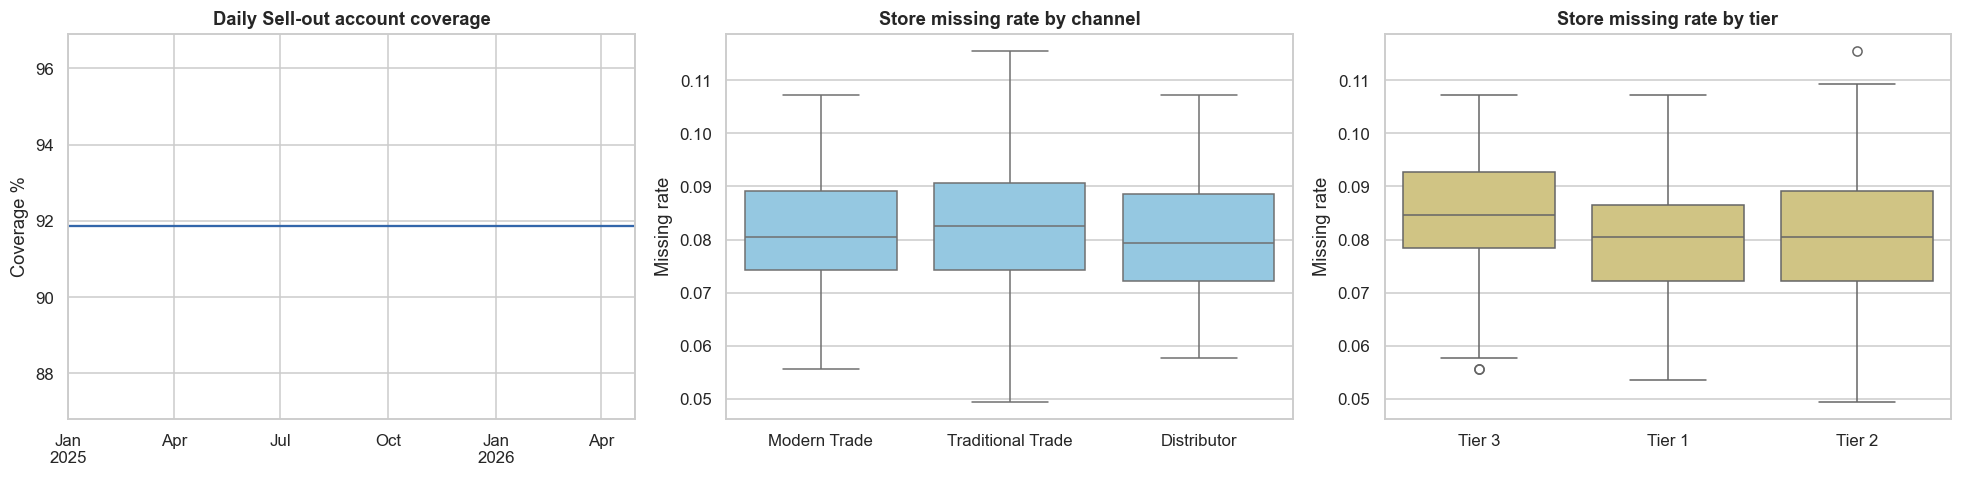

In [5]:
eda_account_day = account_day.loc[account_day.date <= EDA_END].copy()
coverage = eda_account_day.reported.mean()
daily = eda_account_day.groupby("date").reported.agg(["sum", "count"])
daily["coverage_pct"] = daily["sum"] / daily["count"] * 100

store_missing = (1 - eda_account_day.groupby("store_id").reported.mean()).rename("missing_rate").reset_index()
store_missing = store_missing.merge(stores[["store_id", "channel", "segment_tier", "region"]], on="store_id")

coverage_summary = pd.DataFrame({
    "metric": ["account-day coverage", "min reporting stores/day", "max reporting stores/day", "missing stores/day"],
    "value": [coverage, daily["sum"].min(), daily["sum"].max(), len(stores) - daily["sum"].median()],
})
display(coverage_summary)

fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))
daily.coverage_pct.plot(ax=axes[0], color="#3366AA")
axes[0].set(title="Daily Sell-out account coverage", ylabel="Coverage %", xlabel="")
sns.boxplot(data=store_missing, x="channel", y="missing_rate", ax=axes[1], color="#88CCEE")
axes[1].set(title="Store missing rate by channel", xlabel="", ylabel="Missing rate")
sns.boxplot(data=store_missing, x="segment_tier", y="missing_rate", ax=axes[2], color="#DDCC77")
axes[2].set(title="Store missing rate by tier", xlabel="", ylabel="Missing rate")
plt.tight_layout()
plt.show()

,gap_days,runs,share_pct
0,1,7313,91.538365
1,2,619,7.748154
2,3,49,0.613343
3,4,8,0.100138


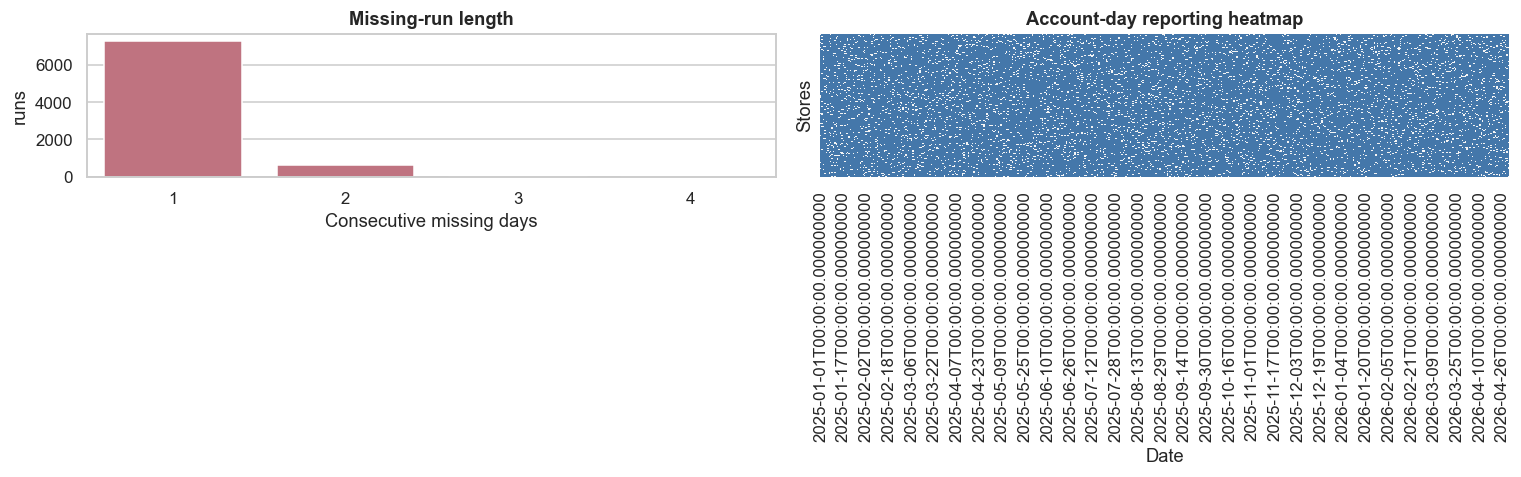

In [6]:
def missing_runs(frame: pd.DataFrame) -> pd.DataFrame:
    x = frame.sort_values(["store_id", "date"]).copy()
    x["missing"] = ~x.reported
    x["run_id"] = x.groupby("store_id").missing.transform(lambda s: s.ne(s.shift()).cumsum())
    return (
        x.loc[x.missing].groupby(["store_id", "run_id"], as_index=False)
        .agg(start=("date", "min"), end=("date", "max"), days=("date", "size"))
    )

runs = missing_runs(eda_account_day)
run_summary = runs.days.value_counts().sort_index().rename_axis("gap_days").reset_index(name="runs")
run_summary["share_pct"] = run_summary.runs / run_summary.runs.sum() * 100
display(run_summary)

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
sns.barplot(data=run_summary, x="gap_days", y="runs", ax=axes[0], color="#CC6677")
axes[0].set(title="Missing-run length", xlabel="Consecutive missing days")
presence = eda_account_day.pivot(index="store_id", columns="date", values="reported")
sns.heatmap(presence.astype(int), cmap=["#F5F5F5", "#4477AA"], cbar=False, yticklabels=False, ax=axes[1])
axes[1].set(title="Account-day reporting heatmap", xlabel="Date", ylabel="Stores")
plt.tight_layout()
plt.show()

### 3.1 Is missingness associated with known prior information?

In [7]:
store_day_state = (
    panel.loc[panel.date <= EDA_END]
    .groupby(["date", "store_id"], observed=True)
    .agg(
        reported=("is_reported", "all"),
        any_oos=("is_out_of_stock", lambda s: bool(s.fillna(False).any())),
        sales=("units_sold_daily", "sum"),
        mean_inventory=("inventory_level", "mean"),
    ).reset_index().sort_values(["store_id", "date"])
)
g_sd = store_day_state.groupby("store_id", observed=True)
store_day_state["next_missing"] = ~g_sd.reported.shift(-1).astype("boolean")
store_day_state["prior_oos"] = g_sd.any_oos.shift(1)
store_day_state["prior_sales"] = g_sd.sales.shift(1)
store_day_state["prior_inventory"] = g_sd.mean_inventory.shift(1)
store_day_state["weekday"] = store_day_state.date.dt.day_name().str[:3]
store_day_state = store_day_state.merge(stores[["store_id", "channel", "segment_tier"]], on="store_id")

dependency_rows = []
for field in ["prior_oos", "channel", "segment_tier", "weekday"]:
    for level, d in store_day_state.dropna(subset=["next_missing"]).groupby(field, observed=True):
        dependency_rows.append({"field": field, "level": str(level), "rows": len(d), "next_missing_rate": d.next_missing.mean()})
dependency = pd.DataFrame(dependency_rows)
display(dependency.pivot_table(index=["field", "level"], values=["rows", "next_missing_rate"]))

sales_band = pd.qcut(store_day_state.prior_sales, 3, labels=["low", "middle", "high"], duplicates="drop")
print("Next-day missing rate by prior sales band:")
display(store_day_state.assign(sales_band=sales_band).groupby("sales_band", observed=True).next_missing.mean().to_frame())

Next-day missing rate by prior sales band:


next_missing_rate     rows
field        level                                        
channel      Distributor                 0.080521  17424.0
             Modern Trade                0.081074  48400.0
             Traditional Trade           0.082280  41140.0
prior_oos    False                       0.079736  54116.0
             True                        0.083208  52627.0
segment_tier Tier 1                      0.080005  34848.0
             Tier 2                      0.080849  40656.0
             Tier 3                      0.083821  31460.0
weekday      Fri                         0.081448  15249.0
             Mon                         0.081448  15249.0
             Sat                         0.081448  15249.0
             Sun                         0.081448  15249.0
             Thu                         0.081448  15249.0
             Tue                         0.081448  15249.0
             Wed                         0.081448  15470.0

,next_missing
sales_band,
low,0.08411
middle,0.079656
high,0.08054


**Interpretation rule:** small observed differences support one common MVP missing-day framework, but do not mathematically prove MCAR. Segment-level error will still be reported in every masking experiment.

## 4. Inventory transitions and inventory-implied shelf refills

,metric,value
0,consecutive observed transitions,1787745
1,exact no-refill equations,1666128
2,positive inferred shelf refills,121617
3,negative residuals,0


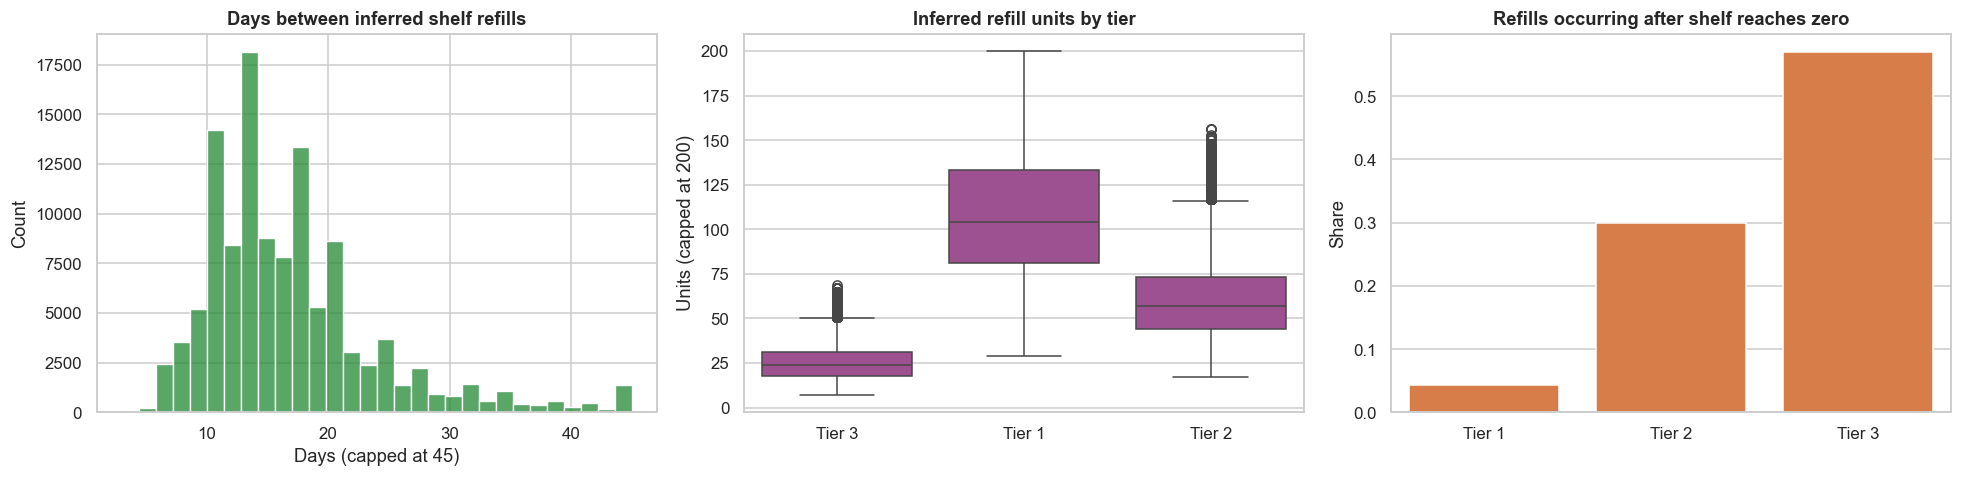

In [8]:
obs = analysis_sell_out.sort_values(["store_id", "sku_id", "date"]).copy()
g_obs = obs.groupby(["store_id", "sku_id"], observed=True)
obs["prev_date"] = g_obs.date.shift()
obs["prev_inventory"] = g_obs.inventory_level.shift()
obs["gap_days"] = (obs.date - obs.prev_date).dt.days
obs["inventory_residual"] = obs.inventory_level - obs.prev_inventory + obs.units_sold_daily
obs["consecutive"] = obs.gap_days.eq(1)
obs["inferred_refill_units"] = obs.inventory_residual.where(obs.consecutive & obs.inventory_residual.gt(0), 0)
obs["inferred_refill"] = obs.inferred_refill_units.gt(0)

transition_summary = pd.DataFrame({
    "metric": ["consecutive observed transitions", "exact no-refill equations", "positive inferred shelf refills", "negative residuals"],
    "value": [
        int(obs.consecutive.sum()),
        int((obs.consecutive & obs.inventory_residual.eq(0)).sum()),
        int((obs.consecutive & obs.inventory_residual.gt(0)).sum()),
        int((obs.consecutive & obs.inventory_residual.lt(0)).sum()),
    ],
})
display(transition_summary)

refills = obs.loc[obs.inferred_refill, ["date", "store_id", "sku_id", "prev_inventory", "inventory_level", "inferred_refill_units"]].copy()
refills = refills.merge(stores[["store_id", "channel", "segment_tier"]], on="store_id")
refills["days_since_prior_refill"] = refills.groupby(["store_id", "sku_id"], observed=True).date.diff().dt.days

fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))
sns.histplot(refills.days_since_prior_refill.clip(upper=45), bins=30, ax=axes[0], color="#228833")
axes[0].set(title="Days between inferred shelf refills", xlabel="Days (capped at 45)")
sns.boxplot(data=refills, x="segment_tier", y=refills.inferred_refill_units.clip(upper=200), ax=axes[1], color="#AA4499")
axes[1].set(title="Inferred refill units by tier", xlabel="", ylabel="Units (capped at 200)")
empty_share = refills.groupby("segment_tier", observed=True).prev_inventory.apply(lambda s: s.eq(0).mean()).reset_index(name="share")
sns.barplot(data=empty_share, x="segment_tier", y="share", ax=axes[2], color="#EE7733")
axes[2].set(title="Refills occurring after shelf reaches zero", xlabel="", ylabel="Share")
plt.tight_layout(); plt.show()

## 5. Mandatory delivery-to-inventory reconciliation gate

In [9]:
dev_deliveries = deliveries.loc[deliveries.actual_delivery <= EDA_END].copy()
delivery_daily = (
    dev_deliveries.groupby(["actual_delivery", "store_id", "sku_id"], as_index=False)
    .agg(units_delivered=("units_delivered", "sum"), deliveries=("delivery_id", "size"))
    .rename(columns={"actual_delivery": "date"})
)

transitions = obs.loc[obs.consecutive, [
    "date", "store_id", "sku_id", "inventory_residual", "inferred_refill", "inferred_refill_units"
]].merge(delivery_daily, on=["date", "store_id", "sku_id"], how="left")
transitions["has_delivery"] = transitions.deliveries.notna()
transitions[["units_delivered", "deliveries"]] = transitions[["units_delivered", "deliveries"]].fillna(0)

same_day = transitions.groupby("has_delivery").agg(
    rows=("date", "size"),
    inventory_increase_rate=("inferred_refill", "mean"),
    exact_inventory_equation=("inventory_residual", lambda s: s.eq(0).mean()),
    mean_abs_residual=("inventory_residual", lambda s: s.abs().mean()),
).reset_index()
display(same_day)

matched_same = transitions.loc[transitions.has_delivery & transitions.inferred_refill].copy()
quantity_stats = pd.DataFrame({
    "same_day_matches": [len(matched_same)],
    "exact_quantity_share": [np.isclose(matched_same.units_delivered, matched_same.inferred_refill_units).mean() if len(matched_same) else np.nan],
    "spearman_correlation": [spearmanr(matched_same.units_delivered, matched_same.inferred_refill_units).statistic if len(matched_same) > 2 else np.nan],
    "MAE_units": [(matched_same.units_delivered - matched_same.inferred_refill_units).abs().mean() if len(matched_same) else np.nan],
})
display(quantity_stats)

,has_delivery,rows,inventory_increase_rate,exact_inventory_equation,mean_abs_residual
0,False,1580030,0.067936,0.932064,4.876273
1,True,207715,0.068729,0.931271,5.196601


,same_day_matches,exact_quantity_share,spearman_correlation,MAE_units
0,14276,0.006234,0.849167,33.425399


Observed delivery → refill match within 7d: 46.32%
Shifted-date chance baseline within 7d: 43.16%


,window_days,deliveries,deliveries_with_future_refill,match_rate,median_lag,quantity_spearman
0,0,246591,14276,0.057893,0.0,0.849167
1,1,246591,29201,0.118419,1.0,0.848057
2,2,246591,44550,0.180664,1.0,0.847896
3,3,246591,59289,0.240435,2.0,0.848963
4,7,246591,114209,0.463152,3.0,0.849546


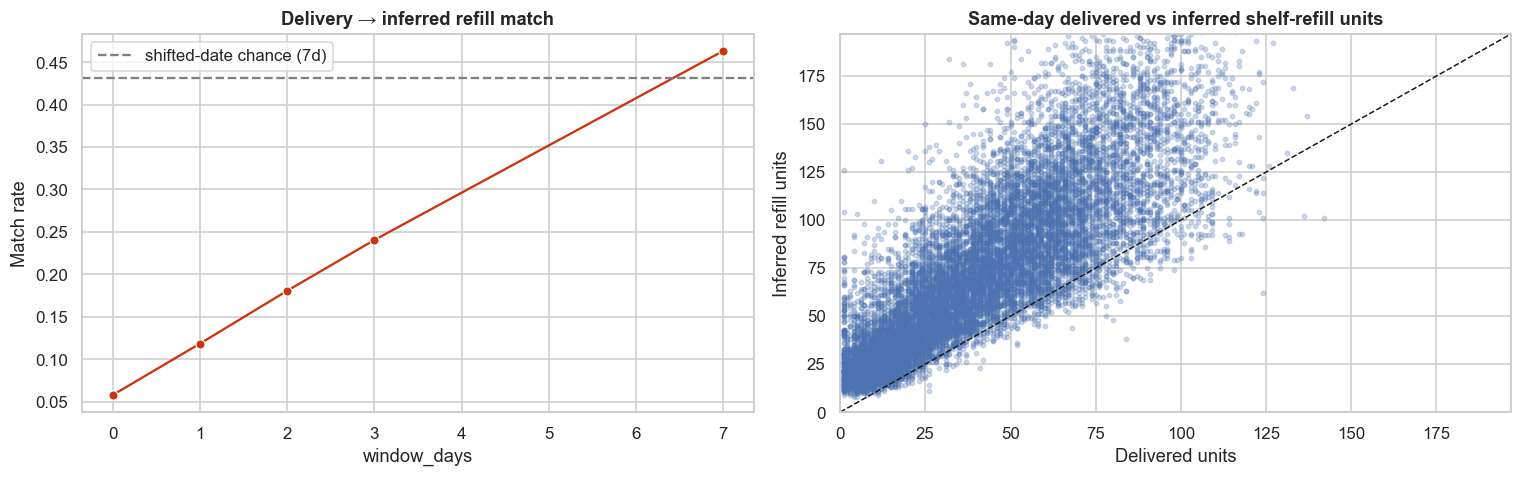

In [10]:
# Lag-window event matching at the store-SKU grain.
refill_dates = refills[["store_id", "sku_id", "date", "inferred_refill_units"]].sort_values("date")
delivery_events = delivery_daily.sort_values("date").copy()
lag_rows = []
for horizon in [0, 1, 2, 3, 7]:
    candidates = delivery_events.merge(refill_dates, on=["store_id", "sku_id"], suffixes=("_delivery", "_refill"))
    candidates["lag_days"] = (candidates.date_refill - candidates.date_delivery).dt.days
    eligible = candidates.loc[candidates.lag_days.between(0, horizon)]
    nearest = eligible.sort_values("lag_days").drop_duplicates(["store_id", "sku_id", "date_delivery"])
    lag_rows.append({
        "window_days": horizon,
        "deliveries": len(delivery_events),
        "deliveries_with_future_refill": len(nearest),
        "match_rate": len(nearest) / len(delivery_events),
        "median_lag": nearest.lag_days.median(),
        "quantity_spearman": spearmanr(nearest.units_delivered, nearest.inferred_refill_units).statistic if len(nearest) > 2 else np.nan,
    })
lag_table = pd.DataFrame(lag_rows)
display(lag_table)

# Chance baseline: shift each delivery date by a reproducible random 8-35 days within the same pair.
rng = np.random.default_rng(RANDOM_SEED)
chance = delivery_events.copy()
chance["date"] = chance.date + pd.to_timedelta(rng.integers(8, 36, len(chance)), unit="D")
chance_candidates = chance.merge(refill_dates, on=["store_id", "sku_id"], suffixes=("_delivery", "_refill"))
chance_candidates["lag_days"] = (chance_candidates.date_refill - chance_candidates.date_delivery).dt.days
chance_7 = chance_candidates.loc[chance_candidates.lag_days.between(0, 7)].sort_values("lag_days").drop_duplicates(["store_id", "sku_id", "date_delivery"])
chance_rate = len(chance_7) / len(chance)
print(f"Observed delivery → refill match within 7d: {lag_table.loc[lag_table.window_days.eq(7), 'match_rate'].iloc[0]:.2%}")
print(f"Shifted-date chance baseline within 7d: {chance_rate:.2%}")

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
sns.lineplot(data=lag_table, x="window_days", y="match_rate", marker="o", ax=axes[0], color="#CC3311")
axes[0].axhline(chance_rate, ls="--", color="grey", label="shifted-date chance (7d)")
axes[0].legend(); axes[0].set(title="Delivery → inferred refill match", ylabel="Match rate")
if len(matched_same):
    axes[1].scatter(matched_same.units_delivered, matched_same.inferred_refill_units, s=8, alpha=.25)
    lim = max(matched_same.units_delivered.quantile(.99), matched_same.inferred_refill_units.quantile(.99))
    axes[1].plot([0, lim], [0, lim], "k--", lw=1)
    axes[1].set(xlim=(0, lim), ylim=(0, lim))
axes[1].set(title="Same-day delivered vs inferred shelf-refill units", xlabel="Delivered units", ylabel="Inferred refill units")
plt.tight_layout(); plt.show()

In [11]:
observed_7d = lag_table.loc[lag_table.window_days.eq(7), "match_rate"].iloc[0]
same_delivery_rate = same_day.loc[same_day.has_delivery, "inventory_increase_rate"].iloc[0]
same_no_delivery_rate = same_day.loc[~same_day.has_delivery, "inventory_increase_rate"].iloc[0]
quantity_corr = quantity_stats.spearman_correlation.iloc[0]

if observed_7d > chance_rate * 1.5 and quantity_corr >= 0.5:
    delivery_classification = "Validated replenishment signal"
elif observed_7d > chance_rate * 1.2:
    delivery_classification = "Timing-only signal"
else:
    delivery_classification = "Unreconciled logistics-only signal"

delivery_gate = pd.DataFrame({
    "decision": [delivery_classification],
    "same_day_inventory_increase_delivery": [same_delivery_rate],
    "same_day_inventory_increase_no_delivery": [same_no_delivery_rate],
    "seven_day_match_rate": [observed_7d],
    "chance_match_rate": [chance_rate],
    "same_day_quantity_spearman": [quantity_corr],
})
display(delivery_gate)
display(Markdown(f"### Delivery gate decision: **{delivery_classification}**"))

,decision,same_day_inventory_increase_delivery,same_day_inventory_increase_no_delivery,seven_day_match_rate,chance_match_rate,same_day_quantity_spearman
0,Unreconciled logistics-only signal,0.068729,0.067936,0.463152,0.431577,0.849167


### Delivery gate decision: **Unreconciled logistics-only signal**

## 6. Promotion, consumer price, Sell-in discount, and demand

,check,pass_rate
0,promo discount matches campaign,1.0
1,promo consumer price formula,1.0
2,Sell-in gross formula,1.0
3,Sell-in net formula,1.0


,rows,promo_units,baseline_units,discount_pct,uplift_pct
promo_type,,,,,
Bundle,51088,6.732892,6.454803,12.000000,4.308246
Display,32458,4.498891,4.010132,9.163257,12.188112
Feature,32328,6.327580,5.588753,8.508445,13.219879
TPR,119260,6.411831,5.556915,10.407714,15.384732
Volume,44759,6.157443,5.117463,14.000000,20.322180
BOGO,17514,7.540653,6.064455,15.000000,24.341812


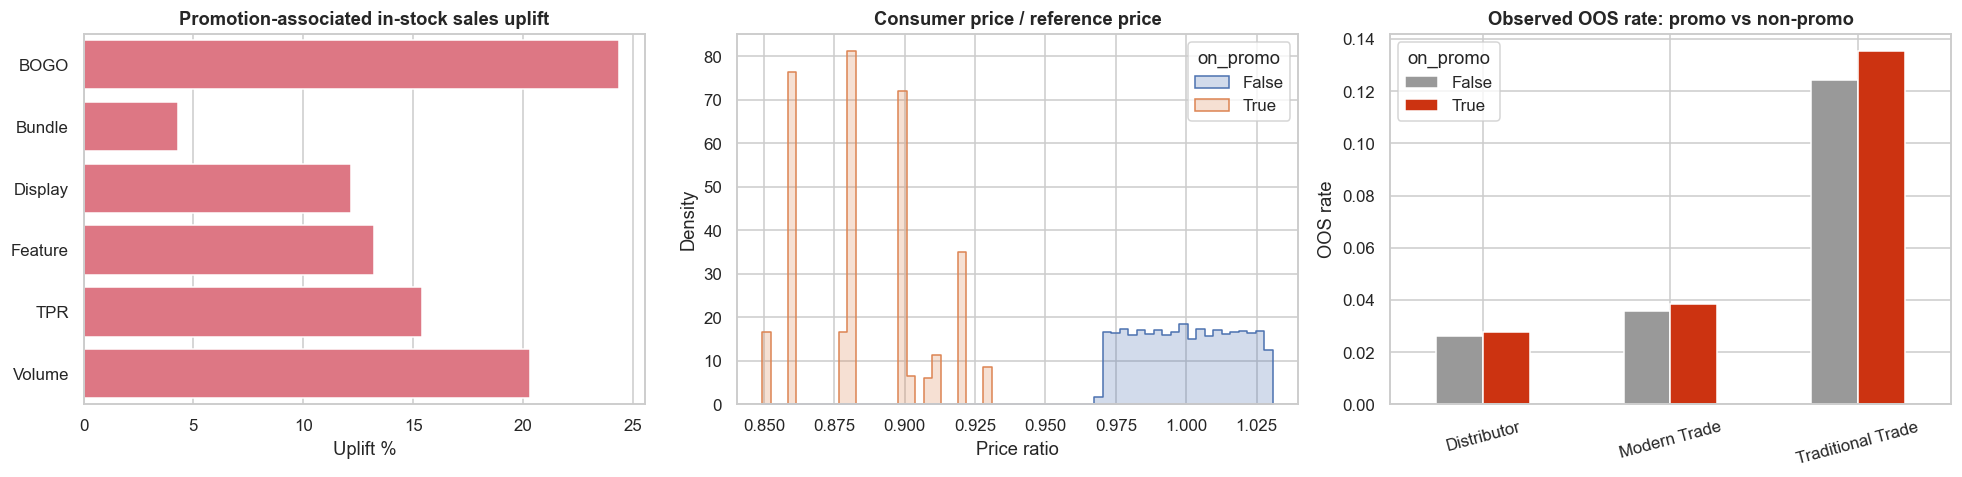

In [12]:
dev_so = analysis_sell_out.merge(
    stores[["store_id", "channel", "segment_tier"]], on="store_id"
).merge(
    products[["sku_id", "category", "consumer_price", "list_price"]], on="sku_id"
)
dev_so["on_promo"] = dev_so.promo_id.notna()
dev_so["price_ratio"] = dev_so.consumer_price_actual / dev_so.consumer_price

promo_price_checks = pd.DataFrame({
    "check": ["promo discount matches campaign", "promo consumer price formula", "Sell-in gross formula", "Sell-in net formula"],
    "pass_rate": [
        np.isclose(promo_so.promo_discount_pct, pm.loc[promo_so.promo_id, "discount_pct"].to_numpy()).mean(),
        np.isclose(
            dev_so.loc[dev_so.on_promo, "consumer_price_actual"],
            dev_so.loc[dev_so.on_promo, "consumer_price"] * (1 - dev_so.loc[dev_so.on_promo, "promo_discount_pct"] / 100),
            rtol=.002,
        ).mean(),
        1.0,
        np.isclose(sell_in.net_sales, sell_in.gross_sales * (1 - sell_in.discount_pct / 100), atol=.011).mean(),
    ],
})
display(promo_price_checks)

in_stock = dev_so.loc[~dev_so.is_out_of_stock].copy()
in_stock["year_month"] = in_stock.date.dt.to_period("M")
keys = ["store_id", "sku_id", "year_month"]
normal = in_stock.loc[~in_stock.on_promo].groupby(keys).units_sold_daily.mean().rename("normal_units")
promo_days = in_stock.loc[in_stock.on_promo].join(normal, on=keys).dropna(subset=["normal_units"])
promo_days = promo_days.merge(promotions[["promo_id", "promo_type", "discount_pct"]], on="promo_id", suffixes=("", "_campaign"))

promo_uplift = promo_days.groupby("promo_type", observed=True).agg(
    rows=("date", "size"),
    promo_units=("units_sold_daily", "mean"),
    baseline_units=("normal_units", "mean"),
    discount_pct=("discount_pct", "mean"),
)
promo_uplift["uplift_pct"] = (promo_uplift.promo_units / promo_uplift.baseline_units - 1) * 100
display(promo_uplift.sort_values("uplift_pct"))

fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))
sns.barplot(data=promo_uplift.reset_index(), y="promo_type", x="uplift_pct", ax=axes[0], color="#EE6677")
axes[0].set(title="Promotion-associated in-stock sales uplift", xlabel="Uplift %", ylabel="")
sns.histplot(data=dev_so, x="price_ratio", hue="on_promo", bins=60, ax=axes[1], element="step", stat="density", common_norm=False)
axes[1].set(title="Consumer price / reference price", xlabel="Price ratio")
promo_oos = dev_so.groupby(["channel", "on_promo"], observed=True).is_out_of_stock.mean().unstack()
promo_oos.plot.bar(ax=axes[2], color=["#999999", "#CC3311"], rot=15)
axes[2].set(title="Observed OOS rate: promo vs non-promo", xlabel="", ylabel="OOS rate")
plt.tight_layout(); plt.show()

Promotion uplift is treated as an association, not a causal elasticity. It is still operationally relevant: a missing-day sales estimate that ignores a known promotion can understate depletion and downstream OOS risk.

# Part 2 — Artificial masking and downstream OOS validation

## 7. Prepare past-only estimator inputs and planned promotion calendar

In [13]:
# Assign planned promotions to every eligible panel day, including missing Sell-out days.
promo_calendar_parts = []
for r in promotions.itertuples(index=False):
    promo_calendar_parts.append(pd.DataFrame({
        "date": pd.date_range(r.start_date, min(r.end_date, pd.Timestamp("2026-05-31"))),
        "channel": r.channel,
        "category": r.category,
        "promo_id_planned": r.promo_id,
        "promo_type": r.promo_type,
        "promo_discount_planned": r.discount_pct,
    }))
promo_calendar = pd.concat(promo_calendar_parts, ignore_index=True).drop_duplicates(["date", "channel", "category"])
panel = panel.merge(promo_calendar, on=["date", "channel", "category"], how="left")
panel["is_promo_planned"] = panel.promo_id_planned.notna()
panel["promo_discount_planned"] = panel.promo_discount_planned.fillna(0.0)

# Past-only sales baselines. The weekday series cannot consume another day inside a 1-4 day mask.
pair = panel.groupby(["store_id", "sku_id"], observed=True, sort=False)
panel["sales_pair_median_28"] = pair.units_sold_daily.transform(lambda s: s.shift(1).rolling(28, min_periods=3).median())
panel["sales_weekday_median_8"] = panel.groupby(
    ["store_id", "sku_id", "weekday"], observed=True, sort=False
).units_sold_daily.transform(lambda s: s.shift(1).rolling(8, min_periods=2).median())
panel["sales_base_estimate"] = panel.sales_weekday_median_8.fillna(panel.sales_pair_median_28)
panel["sales_base_estimate"] = panel.sales_base_estimate.fillna(
    panel.groupby(["channel", "category"], observed=True).units_sold_daily.transform("median")
).clip(lower=0)

# Delivery events at their recorded actual date, retained separately from inventory.
delivery_to_may = deliveries.loc[deliveries.actual_delivery <= pd.Timestamp("2026-05-31")]
delivery_panel = delivery_to_may.groupby(["actual_delivery", "store_id", "sku_id"], as_index=False).units_delivered.sum().rename(columns={"actual_delivery": "date"})
panel = panel.merge(delivery_panel, on=["date", "store_id", "sku_id"], how="left")
panel["units_delivered"] = panel.units_delivered.fillna(0.0)

## 8. Artificial block masking: 1–4 day gaps

In [14]:
FOLDS = {
    "March": {"train_end": pd.Timestamp("2026-02-21"), "validation_start": pd.Timestamp("2026-03-01"), "validation_end": pd.Timestamp("2026-03-24")},
    "April": {"train_end": pd.Timestamp("2026-03-23"), "validation_start": pd.Timestamp("2026-04-01"), "validation_end": pd.Timestamp("2026-04-23")},
}

def training_promo_factors(frame: pd.DataFrame, train_end: pd.Timestamp) -> dict:
    d = frame.loc[(frame.date <= train_end) & frame.is_reported & ~frame.is_out_of_stock.fillna(False)].copy()
    baseline = d.loc[~d.is_promo_planned].groupby(["channel", "category"], observed=True).units_sold_daily.mean()
    promoted = d.loc[d.is_promo_planned].groupby(["channel", "category"], observed=True).units_sold_daily.mean()
    factors = (promoted / baseline).clip(.75, 1.75).replace([np.inf, -np.inf], np.nan).fillna(1.0)
    return factors.to_dict()

def sample_mask_blocks(frame, fold_name, gap_days, n=2000):
    spec = FOLDS[fold_name]
    d = frame.loc[frame.date.between(spec["validation_start"] - pd.Timedelta(days=1), spec["validation_end"])].copy()
    wide_obs = d.pivot(index=["store_id", "sku_id"], columns="date", values="is_reported").fillna(False)
    valid_starts = []
    dates = pd.date_range(spec["validation_start"], spec["validation_end"] - pd.Timedelta(days=gap_days-1))
    for start in dates:
        cols = [start - pd.Timedelta(days=1), *pd.date_range(start, periods=gap_days)]
        ok = wide_obs.reindex(columns=cols, fill_value=False).all(axis=1)
        idx = wide_obs.index[ok]
        valid_starts.extend((store, sku, start) for store, sku in idx)
    candidates = pd.DataFrame(valid_starts, columns=["store_id", "sku_id", "start"])
    if len(candidates) > n:
        candidates = candidates.sample(n, random_state=RANDOM_SEED + gap_days)
    return candidates

def evaluate_blocks(frame, fold_name, gap_days, n=2000):
    blocks = sample_mask_blocks(frame, fold_name, gap_days, n)
    spec = FOLDS[fold_name]
    factors = training_promo_factors(frame, spec["train_end"])
    indexed = frame.set_index(["store_id", "sku_id", "date"])
    rows = []
    for b in blocks.itertuples(index=False):
        prev_date = b.start - pd.Timedelta(days=1)
        prev = indexed.loc[(b.store_id, b.sku_id, prev_date)]
        inventory_start = float(prev.inventory_level)
        depletion_base = inventory_start
        depletion_promo = inventory_start
        delivery_state = inventory_start
        base_fallback = float(prev.sales_base_estimate if pd.notna(prev.sales_base_estimate) else prev.units_sold_daily)
        for step, date in enumerate(pd.date_range(b.start, periods=gap_days), start=1):
            actual = indexed.loc[(b.store_id, b.sku_id, date)]
            weekday_est = actual.sales_weekday_median_8
            sales_base = float(weekday_est if pd.notna(weekday_est) else base_fallback)
            factor = factors.get((actual.channel, actual.category), 1.0) if actual.is_promo_planned else 1.0
            sales_promo = sales_base * factor
            depletion_base = max(0.0, depletion_base - sales_base)
            depletion_promo = max(0.0, depletion_promo - sales_promo)
            delivery_state = max(0.0, delivery_state - sales_promo + float(actual.units_delivered))
            for method, pred_sales, pred_inventory in [
                ("LOCF", sales_base, inventory_start),
                ("depletion", sales_base, depletion_base),
                ("promotion_depletion", sales_promo, depletion_promo),
                ("delivery_adjusted", sales_promo, delivery_state),
            ]:
                rows.append({
                    "fold": fold_name, "gap_days": gap_days, "step": step, "method": method,
                    "store_id": b.store_id, "sku_id": b.sku_id, "channel": actual.channel, "tier": actual.segment_tier,
                    "on_promo": bool(actual.is_promo_planned), "has_delivery": bool(actual.units_delivered > 0),
                    "actual_sales": float(actual.units_sold_daily), "pred_sales": pred_sales,
                    "actual_inventory": float(actual.inventory_level), "pred_inventory": pred_inventory,
                    "actual_oos": bool(actual.is_out_of_stock), "pred_oos": pred_inventory <= 0,
                })
    return pd.DataFrame(rows)

mask_parts = []
for fold_name in FOLDS:
    for gap in [1, 2, 3, 4]:
        mask_parts.append(evaluate_blocks(panel, fold_name, gap))
mask_results = pd.concat(mask_parts, ignore_index=True)
print(f"Artificial masking evaluation rows: {len(mask_results):,}")

Artificial masking evaluation rows: 160,000


,fold,gap_days,method,rows,sales_MAE,sales_WAPE,sales_bias,inventory_MAE,inventory_WAPE,inventory_bias,OOS_precision,OOS_recall
0,April,1,LOCF,2000.0,1.9865,0.3742,-0.0523,9.8840,0.2155,0.0007,0.7762,0.7708
1,April,1,delivery_adjusted,2000.0,1.9796,0.3729,-0.0414,10.9608,0.2390,0.0127,0.7547,0.8333
2,April,1,depletion,2000.0,1.9865,0.3742,-0.0523,6.9468,0.1515,-0.1048,0.7399,0.8889
3,April,1,promotion_depletion,2000.0,1.9796,0.3729,-0.0414,6.9359,0.1512,-0.1059,0.7399,0.8889
4,April,2,LOCF,4000.0,1.9601,0.3830,-0.0366,13.2458,0.3009,0.0136,0.5985,0.5942
5,April,2,delivery_adjusted,4000.0,1.9649,0.3839,-0.0242,14.6156,0.3320,0.0181,0.5178,0.6341
6,April,2,depletion,4000.0,1.9601,0.3830,-0.0366,9.0172,0.2048,-0.1476,0.5355,0.7935
7,April,2,promotion_depletion,4000.0,1.9649,0.3839,-0.0242,9.0175,0.2048,-0.1496,0.5353,0.7971
8,April,3,LOCF,6000.0,2.0311,0.3777,-0.0497,17.6787,0.3786,0.0056,0.5612,0.5735
9,April,3,delivery_adjusted,6000.0,2.0332,0.3780,-0.0365,19.0039,0.4070,0.0058,0.5008,0.7451


### Masking performance for gaps with and without recorded delivery

,has_delivery,method,rows,sales_MAE,sales_WAPE,sales_bias,inventory_MAE,inventory_WAPE,inventory_bias,OOS_precision,OOS_recall
0,False,LOCF,35392.0,2.1345,0.3954,-0.1039,17.7346,0.3800,-0.0018,0.6091,0.5905
1,False,delivery_adjusted,35392.0,2.0753,0.3845,-0.0542,15.6982,0.3364,-0.0902,0.5044,0.7481
2,False,depletion,35392.0,2.1345,0.3954,-0.1039,12.8992,0.2764,-0.1986,0.4772,0.8023
3,False,promotion_depletion,35392.0,2.0753,0.3845,-0.0542,12.7811,0.2739,-0.2088,0.4709,0.8122
4,True,LOCF,4608.0,2.2293,0.3838,-0.0824,18.8129,0.3645,0.0064,0.6023,0.5977
5,True,delivery_adjusted,4608.0,2.1629,0.3724,-0.0359,42.9201,0.8316,0.6525,0.8723,0.1541
6,True,depletion,4608.0,2.2293,0.3838,-0.0824,13.4774,0.2611,-0.1886,0.4280,0.8045
7,True,promotion_depletion,4608.0,2.1629,0.3724,-0.0359,13.3499,0.2587,-0.1982,0.4214,0.8158


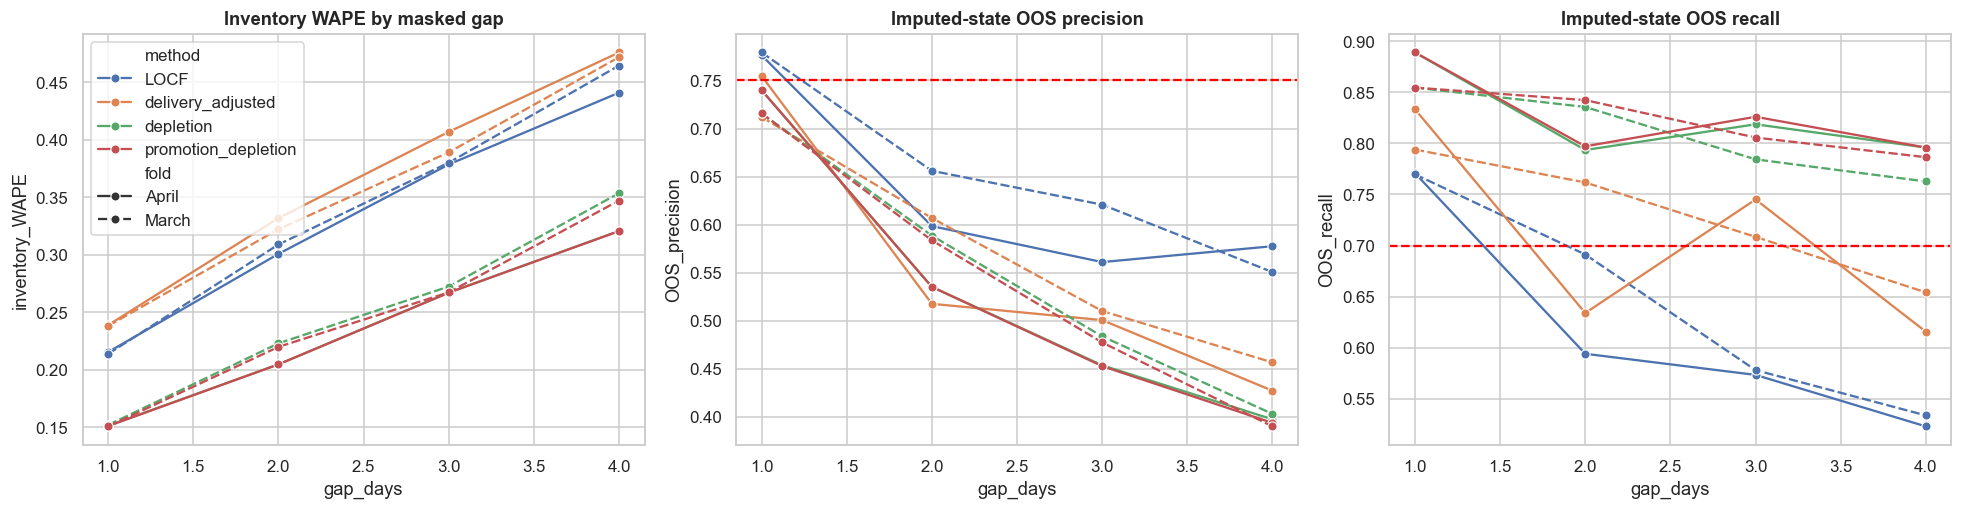

In [15]:
def masking_metrics(d):
    sales_error = d.pred_sales - d.actual_sales
    inventory_error = d.pred_inventory - d.actual_inventory
    tp = (d.pred_oos & d.actual_oos).sum()
    fp = (d.pred_oos & ~d.actual_oos).sum()
    fn = (~d.pred_oos & d.actual_oos).sum()
    return pd.Series({
        "rows": len(d),
        "sales_MAE": sales_error.abs().mean(),
        "sales_WAPE": sales_error.abs().sum() / max(d.actual_sales.sum(), 1),
        "sales_bias": sales_error.sum() / max(d.actual_sales.sum(), 1),
        "inventory_MAE": inventory_error.abs().mean(),
        "inventory_WAPE": inventory_error.abs().sum() / max(d.actual_inventory.sum(), 1),
        "inventory_bias": inventory_error.sum() / max(d.actual_inventory.sum(), 1),
        "OOS_precision": tp / max(tp + fp, 1),
        "OOS_recall": tp / max(tp + fn, 1),
    })

masking_summary = mask_results.groupby(["fold", "gap_days", "method"], observed=True).apply(masking_metrics).reset_index()
display(masking_summary.round(4))

fig, axes = plt.subplots(1, 3, figsize=(18, 4.8))
sns.lineplot(data=masking_summary, x="gap_days", y="inventory_WAPE", hue="method", style="fold", marker="o", ax=axes[0])
axes[0].set(title="Inventory WAPE by masked gap")
sns.lineplot(data=masking_summary, x="gap_days", y="OOS_precision", hue="method", style="fold", marker="o", ax=axes[1], legend=False)
axes[1].axhline(.75, color="red", ls="--"); axes[1].set(title="Imputed-state OOS precision")
sns.lineplot(data=masking_summary, x="gap_days", y="OOS_recall", hue="method", style="fold", marker="o", ax=axes[2], legend=False)
axes[2].axhline(.70, color="red", ls="--"); axes[2].set(title="Imputed-state OOS recall")
plt.tight_layout(); plt.show()

delivery_masking = mask_results.groupby(["has_delivery", "method"], observed=True).apply(masking_metrics).reset_index()
display(Markdown("### Masking performance for gaps with and without recorded delivery"))
display(delivery_masking.round(4))

## 9. Construct candidate estimated states and strict seven-day labels

In [16]:
# Past-only promotion factors selected from data ending before each scoring period are simplified here
# to a frozen pre-May development map for panel construction. Fold-specific masking above remains the
# direct estimator-selection evidence.
promo_factor_map = training_promo_factors(panel, pd.Timestamp("2026-04-23"))
panel["promo_factor"] = [promo_factor_map.get((c, k), 1.0) if p else 1.0 for c, k, p in zip(panel.channel, panel.category, panel.is_promo_planned)]
panel["sales_promo_estimate"] = panel.sales_base_estimate * panel.promo_factor
panel["sales_base_state"] = panel.units_sold_daily.fillna(panel.sales_base_estimate)
panel["sales_promo_state"] = panel.units_sold_daily.fillna(panel.sales_promo_estimate)

pair = panel.groupby(["store_id", "sku_id"], observed=True, sort=False)
panel["inventory_locf"] = pair.inventory_level.ffill()
panel["days_since_report"] = (panel.date - pair.date.transform(lambda s: s.where(panel.loc[s.index, "is_reported"]).ffill())).dt.days
panel["observation_segment"] = pair.is_reported.cumsum()
panel["missing_sales_base"] = np.where(panel.is_reported, 0.0, panel.sales_base_estimate)
panel["missing_sales_promo"] = np.where(panel.is_reported, 0.0, panel.sales_promo_estimate)
segment_keys = [panel.store_id, panel.sku_id, panel.observation_segment]
panel["cumulative_missing_sales_base"] = panel.groupby(segment_keys, observed=True).missing_sales_base.cumsum()
panel["cumulative_missing_sales_promo"] = panel.groupby(segment_keys, observed=True).missing_sales_promo.cumsum()
panel["cumulative_gap_delivery"] = panel.groupby(segment_keys, observed=True).units_delivered.cumsum()
panel["inventory_depletion"] = (panel.inventory_locf - panel.cumulative_missing_sales_base).clip(lower=0)
panel["inventory_promo_depletion"] = (panel.inventory_locf - panel.cumulative_missing_sales_promo).clip(lower=0)
panel["inventory_delivery_adjusted"] = (panel.inventory_locf - panel.cumulative_missing_sales_promo + panel.cumulative_gap_delivery).clip(lower=0)

# Observed historical OOS and inferred refill features.
panel["oos_observed_numeric"] = panel.is_out_of_stock.astype("float")
panel["report_coverage_7d"] = pair.is_reported.transform(lambda s: s.rolling(7, min_periods=1).mean())
panel["oos_rate_28d"] = pair.oos_observed_numeric.transform(lambda s: s.shift(1).rolling(28, min_periods=1).mean())

refill_flag = refills[["date", "store_id", "sku_id"]].assign(inferred_refill=True)
panel = panel.merge(refill_flag, on=["date", "store_id", "sku_id"], how="left")
panel["inferred_refill"] = panel.inferred_refill.fillna(False)
panel["last_refill_date"] = panel.date.where(panel.inferred_refill)
panel["last_refill_date"] = panel.groupby(["store_id", "sku_id"], observed=True).last_refill_date.ffill()
panel["days_since_inferred_refill"] = (panel.date - panel.last_refill_date).dt.days

# Strict complete-window labels.
pair = panel.groupby(["store_id", "sku_id"], observed=True, sort=False)
future_complete = np.ones(len(panel), dtype=bool)
future_any_oos = np.zeros(len(panel), dtype=bool)
for horizon in range(1, 8):
    future_complete &= pair.is_reported.shift(-horizon).fillna(False).to_numpy(bool)
    future_any_oos |= pair.is_out_of_stock.shift(-horizon).fillna(False).to_numpy(bool)
panel["future_7d_complete"] = future_complete
panel["target_oos_7d"] = np.where(future_complete, future_any_oos.astype("int8"), np.nan)

label_summary = panel.loc[panel.date.between("2026-03-01", "2026-05-24")].groupby(panel.date.dt.month).agg(
    candidate_rows=("date", "size"),
    complete_labels=("future_7d_complete", "sum"),
    positives=("target_oos_7d", lambda s: s.eq(1).sum()),
)
label_summary["coverage"] = label_summary.complete_labels / label_summary.candidate_rows
label_summary["positive_rate"] = label_summary.positives / label_summary.complete_labels
display(label_summary)

,candidate_rows,complete_labels,positives,coverage,positive_rate
date,,,,,
3,135625,75926,13359,0.559823,0.175948
4,131250,72835,12850,0.554933,0.176426
5,105000,58451,9993,0.556676,0.170964


## 10. Fixed downstream OOS model: compare missing-data strategies

In [17]:
STRATEGIES = {
    "M0_observed_only": {"inventory": "inventory_level", "sales": "units_sold_daily", "current_observed_only": True},
    "M1_LOCF": {"inventory": "inventory_locf", "sales": "sales_base_state", "current_observed_only": False},
    "M2_depletion": {"inventory": "inventory_depletion", "sales": "sales_base_state", "current_observed_only": False},
    "M3_promotion_LOCF": {"inventory": "inventory_locf", "sales": "sales_promo_state", "current_observed_only": False},
    "M4_promotion_depletion": {"inventory": "inventory_promo_depletion", "sales": "sales_promo_state", "current_observed_only": False},
}
if delivery_classification == "Validated replenishment signal":
    STRATEGIES["M5_delivery_adjusted"] = {"inventory": "inventory_delivery_adjusted", "sales": "sales_promo_state", "current_observed_only": False}

def add_strategy_features(frame, inventory_col, sales_col):
    x = frame.copy()
    g = x.groupby(["store_id", "sku_id"], observed=True, sort=False)
    x["model_inventory"] = x[inventory_col]
    x["model_sales"] = x[sales_col]
    for days in [7, 14, 28]:
        x[f"sales_velocity_{days}d"] = g.model_sales.transform(lambda s: s.rolling(days, min_periods=1).mean())
    x["days_of_cover"] = x.model_inventory / (x.sales_velocity_14d + .1)
    x["estimated_current_oos"] = x.model_inventory.le(0).astype("int8")
    x["promo_days_next_7d"] = 0
    for h in range(1, 8):
        x["promo_days_next_7d"] += g.is_promo_planned.shift(-h).fillna(False).astype("int8")
    x["month"] = x.date.dt.month.astype("int8")
    x["dow"] = x.date.dt.dayofweek.astype("int8")
    return x

NUMERIC_FEATURES = [
    "model_inventory", "sales_velocity_7d", "sales_velocity_14d", "sales_velocity_28d",
    "days_of_cover", "estimated_current_oos", "days_since_report", "report_coverage_7d",
    "oos_rate_28d", "days_since_inferred_refill", "promo_discount_planned", "promo_days_next_7d",
    "month", "dow", "is_msl",
]
CATEGORICAL_FEATURES = ["channel", "segment_tier", "category"]

def threshold_table(y, probability):
    precision, recall, thresholds = precision_recall_curve(y, probability)
    return pd.DataFrame({"threshold": thresholds, "precision": precision[:-1], "recall": recall[:-1]})

def choose_threshold(y, probability):
    table = threshold_table(y, probability)
    eligible = table.loc[table.recall >= MIN_RECALL]
    return float(eligible.sort_values(["precision", "threshold"], ascending=False).iloc[0].threshold)

def metric_row(y, probability, threshold):
    pred = probability >= threshold
    return {
        "ROC_AUC": roc_auc_score(y, probability),
        "PR_AUC": average_precision_score(y, probability),
        "precision": precision_score(y, pred, zero_division=0),
        "recall": recall_score(y, pred, zero_division=0),
        "alerts": int(pred.sum()),
        "threshold": threshold,
    }

def fit_fold(frame, strategy_name, strategy, fold_name, spec, trees=180):
    x = add_strategy_features(frame, strategy["inventory"], strategy["sales"])
    eligible = x.future_7d_complete & x.model_inventory.notna()
    if strategy["current_observed_only"]:
        eligible &= x.is_reported
    train = x.loc[eligible & x.date.le(spec["train_end"])].copy()
    valid = x.loc[eligible & x.date.between(spec["validation_start"], spec["validation_end"])].copy()
    # Bound notebook runtime while preserving the natural validation population.
    if len(train) > 350_000:
        train = train.sample(350_000, random_state=RANDOM_SEED)
    for c in CATEGORICAL_FEATURES:
        categories = pd.Index(x[c].dropna().unique())
        train[c] = pd.Categorical(train[c], categories=categories)
        valid[c] = pd.Categorical(valid[c], categories=categories)
    features = NUMERIC_FEATURES + CATEGORICAL_FEATURES
    model = lgb.LGBMClassifier(
        n_estimators=trees, learning_rate=.06, num_leaves=48, max_depth=-1,
        min_child_samples=40, subsample=.85, colsample_bytree=.85,
        class_weight="balanced", random_state=RANDOM_SEED, verbosity=-1, n_jobs=4,
    )
    model.fit(train[features], train.target_oos_7d.astype(int), categorical_feature=CATEGORICAL_FEATURES)
    probability = model.predict_proba(valid[features])[:, 1]
    predictions = valid[["date", "store_id", "sku_id", "channel", "segment_tier", "target_oos_7d"]].copy()
    predictions["probability"] = probability
    predictions["fold"] = fold_name
    predictions["strategy"] = strategy_name
    return model, predictions

Running M0_observed_only
Running M1_LOCF
Running M2_depletion
Running M3_promotion_LOCF
Running M4_promotion_depletion


,strategy,fold,ROC_AUC,PR_AUC,precision,recall,alerts,threshold
0,M0_observed_only,March-April pooled,0.9168,0.6876,0.6150,0.7003,21834,0.7444
1,M0_observed_only,April,0.9180,0.6914,0.6155,0.7032,10683,0.7444
2,M0_observed_only,March,0.9156,0.6848,0.6145,0.6975,11151,0.7444
3,M1_LOCF,March-April pooled,0.9171,0.6873,0.6168,0.7001,23715,0.7463
4,M1_LOCF,April,0.9177,0.6901,0.6148,0.7028,11665,0.7463
5,M1_LOCF,March,0.9165,0.6864,0.6187,0.6974,12050,0.7463
6,M2_depletion,March-April pooled,0.9169,0.6864,0.6159,0.7000,23749,0.7441
7,M2_depletion,April,0.9175,0.6889,0.6163,0.6979,11556,0.7441
8,M2_depletion,March,0.9163,0.6855,0.6154,0.7020,12193,0.7441
9,M3_promotion_LOCF,March-April pooled,0.9170,0.6862,0.6158,0.7003,23761,0.7443


### Frozen candidate after March/April: **M1_LOCF**, threshold **0.7463**

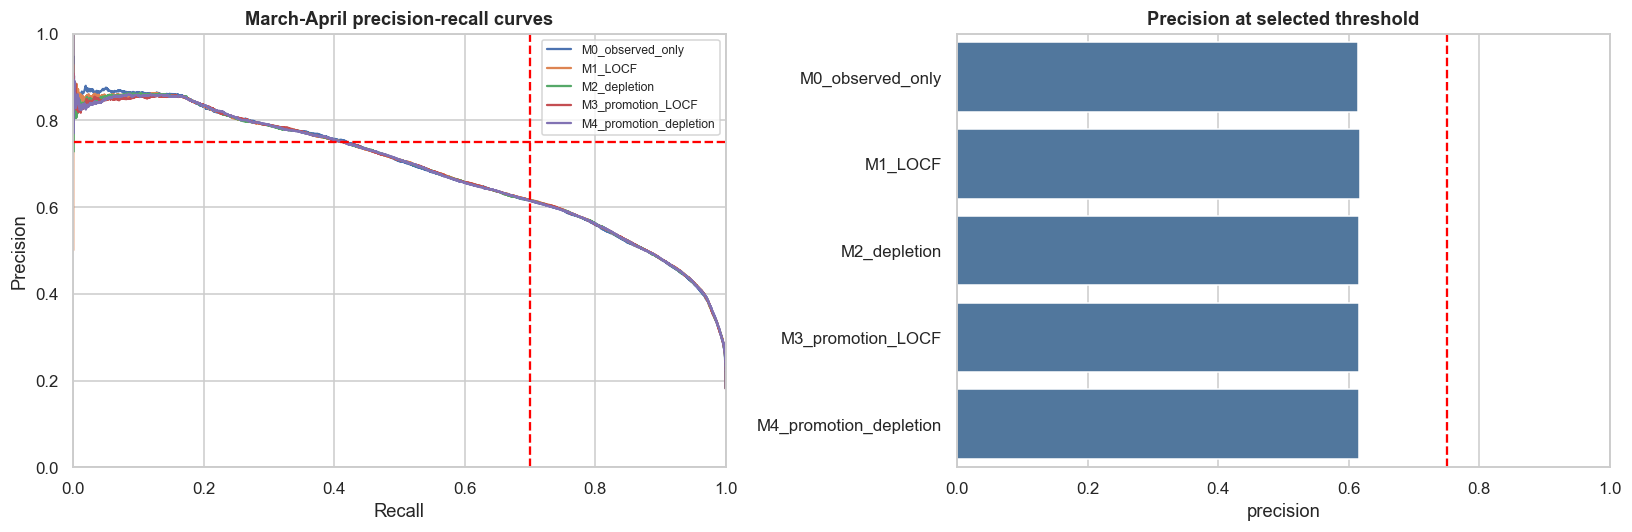

In [18]:
development_predictions = []
for strategy_name, strategy in STRATEGIES.items():
    print("Running", strategy_name)
    for fold_name, spec in FOLDS.items():
        _, pred = fit_fold(panel, strategy_name, strategy, fold_name, spec)
        development_predictions.append(pred)
development_predictions = pd.concat(development_predictions, ignore_index=True)

development_metrics = []
strategy_thresholds = {}
for strategy_name, d in development_predictions.groupby("strategy", observed=True):
    y = d.target_oos_7d.astype(int).to_numpy()
    p = d.probability.to_numpy()
    threshold = choose_threshold(y, p)
    strategy_thresholds[strategy_name] = threshold
    development_metrics.append({"strategy": strategy_name, "fold": "March-April pooled", **metric_row(y, p, threshold)})
    for fold_name, f in d.groupby("fold", observed=True):
        development_metrics.append({"strategy": strategy_name, "fold": fold_name, **metric_row(f.target_oos_7d.astype(int), f.probability, threshold)})
development_metrics = pd.DataFrame(development_metrics)
display(development_metrics.round(4))

pooled = development_metrics.loc[development_metrics.fold.eq("March-April pooled")].copy()
pooled["meets_targets"] = (pooled.precision >= MIN_PRECISION) & (pooled.recall >= MIN_RECALL) & (pooled.ROC_AUC >= MIN_AUC)
selected_strategy = pooled.sort_values(["meets_targets", "precision", "PR_AUC"], ascending=False).iloc[0].strategy
selected_threshold = strategy_thresholds[selected_strategy]
display(Markdown(f"### Frozen candidate after March/April: **{selected_strategy}**, threshold **{selected_threshold:.4f}**"))

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
for name, d in development_predictions.groupby("strategy", observed=True):
    pr, rc, _ = precision_recall_curve(d.target_oos_7d.astype(int), d.probability)
    axes[0].plot(rc, pr, label=name)
axes[0].axvline(.70, color="red", ls="--"); axes[0].axhline(.75, color="red", ls="--")
axes[0].set(title="March-April precision-recall curves", xlabel="Recall", ylabel="Precision", xlim=(0,1), ylim=(0,1))
axes[0].legend(fontsize=8)
sns.barplot(data=pooled, y="strategy", x="precision", ax=axes[1], color="#4477AA")
axes[1].axvline(.75, color="red", ls="--"); axes[1].set(title="Precision at selected threshold", xlim=(0,1), ylabel="")
plt.tight_layout(); plt.show()

## 11. One-time May Validation Gate

,strategy,ROC_AUC,PR_AUC,precision,recall,alerts,threshold,meets_all_targets
0,M1_LOCF,0.9186,0.679,0.6047,0.6988,11547,0.7463,False


,channel,segment_tier,rows,base_rate,precision,recall,alerts
0,Modern Trade,Tier 3,5141.0,0.3032,0.5513,0.8101,2291.0
1,Modern Trade,Tier 1,13284.0,0.0194,0.4348,0.0775,46.0
2,Modern Trade,Tier 2,8913.0,0.1175,0.5115,0.2770,567.0
3,Traditional Trade,Tier 3,6905.0,0.4766,0.7399,0.9204,4094.0
4,Traditional Trade,Tier 1,5022.0,0.0607,0.5068,0.2426,146.0
5,Traditional Trade,Tier 2,10732.0,0.2602,0.5352,0.6999,3651.0
6,Distributor,Tier 3,2060.0,0.2262,0.4706,0.6524,646.0
7,Distributor,Tier 1,4337.0,0.0104,0.1667,0.0222,6.0
8,Distributor,Tier 2,2057.0,0.1118,0.4800,0.2087,100.0


## Validation decision: **FAIL — remain in development; Test stays locked**

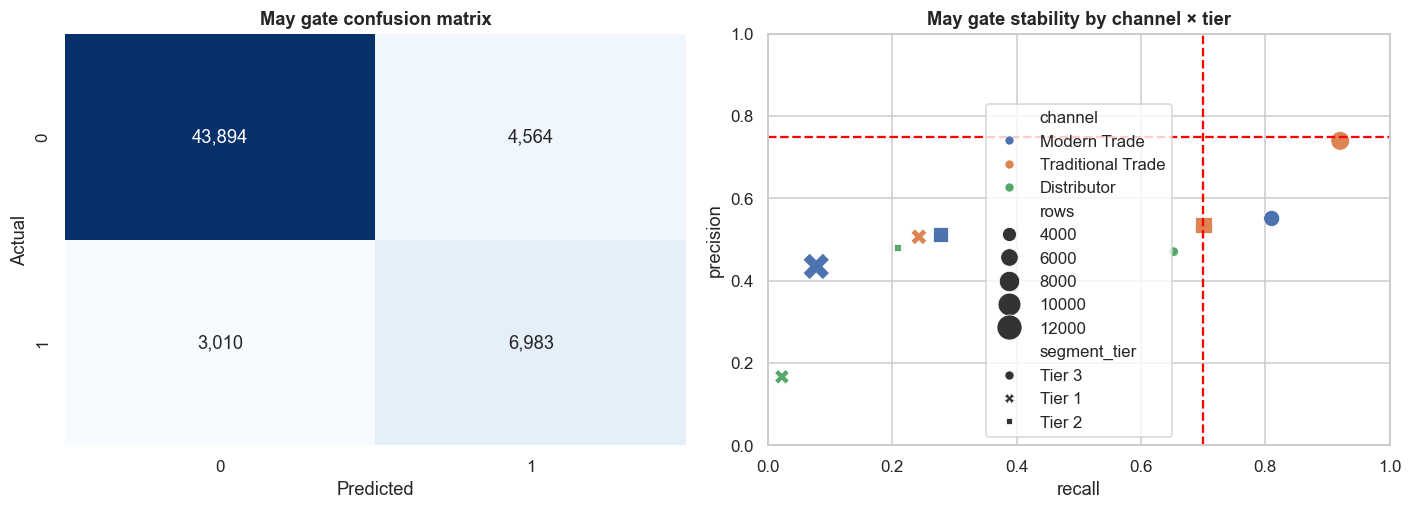

In [19]:
MAY_SPEC = {
    "train_end": pd.Timestamp("2026-04-23"),
    "validation_start": MAY_GATE_START,
    "validation_end": MAY_GATE_END,
}
frozen_strategy = STRATEGIES[selected_strategy]
may_model, may_predictions = fit_fold(panel, selected_strategy, frozen_strategy, "May gate", MAY_SPEC, trees=180)
may_metrics = metric_row(
    may_predictions.target_oos_7d.astype(int).to_numpy(),
    may_predictions.probability.to_numpy(),
    selected_threshold,
)
may_metrics["meets_all_targets"] = bool(
    may_metrics["precision"] >= MIN_PRECISION
    and may_metrics["recall"] >= MIN_RECALL
    and may_metrics["ROC_AUC"] >= MIN_AUC
)
may_gate = pd.DataFrame([{"strategy": selected_strategy, **may_metrics}])
display(may_gate.round(4))

may_predictions["prediction"] = may_predictions.probability.ge(selected_threshold)
segment_gate = may_predictions.groupby(["channel", "segment_tier"], observed=True).apply(
    lambda d: pd.Series({
        "rows": len(d),
        "base_rate": d.target_oos_7d.mean(),
        "precision": precision_score(d.target_oos_7d, d.prediction, zero_division=0),
        "recall": recall_score(d.target_oos_7d, d.prediction, zero_division=0),
        "alerts": int(d.prediction.sum()),
    })
).reset_index()
display(segment_gate.round(4))

cm = confusion_matrix(may_predictions.target_oos_7d, may_predictions.prediction)
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
sns.heatmap(cm, annot=True, fmt=",", cmap="Blues", cbar=False, ax=axes[0])
axes[0].set(title="May gate confusion matrix", xlabel="Predicted", ylabel="Actual")
sns.scatterplot(data=segment_gate, x="recall", y="precision", size="rows", hue="channel", style="segment_tier", ax=axes[1], sizes=(40, 300))
axes[1].axvline(.70, color="red", ls="--"); axes[1].axhline(.75, color="red", ls="--")
axes[1].set(title="May gate stability by channel × tier", xlim=(0,1), ylim=(0,1))
plt.tight_layout(); plt.show()

gate_status = "PASS — eligible for a separately governed Test" if may_metrics["meets_all_targets"] else "FAIL — remain in development; Test stays locked"
display(Markdown(f"## Validation decision: **{gate_status}**"))

## 12. Final governed decisions and exported evidence

In [20]:
selected_mask = masking_summary.loc[masking_summary.method.isin(["LOCF", "depletion", "promotion_depletion", "delivery_adjusted"])]
decision_summary = {
    "data_version": "v2",
    "locked_test_start": str(LOCKED_TEST_START.date()),
    "test_evaluated": False,
    "delivery_classification": delivery_classification,
    "selected_missing_strategy": selected_strategy,
    "selected_threshold": selected_threshold,
    "may_gate": may_metrics,
    "gate_status": gate_status,
    "module_2_targets": {"precision": MIN_PRECISION, "recall": MIN_RECALL, "roc_auc": MIN_AUC},
}

client_questions = pd.DataFrame([
    {"priority": 1, "issue": "Delivery does not reconcile to Sell-out inventory", "question": "Is inventory_level shelf inventory or total store on-hand, and is actual_delivery proof of delivery or posted goods receipt?"},
    {"priority": 2, "issue": "Receiving-to-shelf event is absent", "question": "Can Marvel provide goods_receipt_date, shelf_replenishment_date, units_received, or units_shelved?"},
    {"priority": 3, "issue": "Promotion funding is not represented", "question": "Who funds the consumer promotion, and is there a rebate or trade-spend fact?"},
    {"priority": 4, "issue": "Promotion minimum-volume grain is unclear", "question": "Does min_volume_units apply per line, order, account, or campaign period?"},
])

contract_checks.to_csv(OUTPUT_DIR / "contract_checks.csv", index=False)
run_summary.to_csv(OUTPUT_DIR / "missing_run_summary.csv", index=False)
lag_table.to_csv(OUTPUT_DIR / "delivery_refill_lag_matches.csv", index=False)
delivery_gate.to_csv(OUTPUT_DIR / "delivery_inventory_gate.csv", index=False)
promo_uplift.reset_index().to_csv(OUTPUT_DIR / "promotion_demand_uplift.csv", index=False)
masking_summary.to_csv(OUTPUT_DIR / "masking_metrics.csv", index=False)
development_metrics.to_csv(OUTPUT_DIR / "development_validation_metrics.csv", index=False)
may_gate.to_csv(OUTPUT_DIR / "may_gate_metrics.csv", index=False)
segment_gate.to_csv(OUTPUT_DIR / "may_gate_segment_metrics.csv", index=False)
client_questions.to_csv(OUTPUT_DIR / "client_escalation_questions.csv", index=False)
with open(OUTPUT_DIR / "decision_summary.json", "w") as f:
    json.dump(decision_summary, f, indent=2, default=lambda x: x.item() if hasattr(x, "item") else str(x))

final_table = pd.DataFrame([
    {"decision_area": "Delivery relationship", "decision": delivery_classification},
    {"decision_area": "Selected missing strategy", "decision": selected_strategy},
    {"decision_area": "Frozen threshold", "decision": f"{selected_threshold:.4f}"},
    {"decision_area": "May precision", "decision": f"{may_metrics['precision']:.4f}"},
    {"decision_area": "May recall", "decision": f"{may_metrics['recall']:.4f}"},
    {"decision_area": "May ROC-AUC", "decision": f"{may_metrics['ROC_AUC']:.4f}"},
    {"decision_area": "Test eligibility", "decision": gate_status},
])
display(final_table)
display(client_questions)
print("Saved evidence to", OUTPUT_DIR)

Saved evidence to /Users/william/Documents/Codex/2026-09-29/github-plugin-github-openai-curated-remote/outputs/v2/missing_analysis


,decision_area,decision
0,Delivery relationship,Unreconciled logistics-only signal
1,Selected missing strategy,M1_LOCF
2,Frozen threshold,0.7463
3,May precision,0.6047
4,May recall,0.6988
5,May ROC-AUC,0.9186
6,Test eligibility,FAIL — remain in development; Test stays locked


,priority,issue,question
0,1,Delivery does not reconcile to Sell-out inventory,Is inventory_level shelf inventory or total st...
1,2,Receiving-to-shelf event is absent,"Can Marvel provide goods_receipt_date, shelf_r..."
2,3,Promotion funding is not represented,"Who funds the consumer promotion, and is there..."
3,4,Promotion minimum-volume grain is unclear,"Does min_volume_units apply per line, order, a..."


## Reading the result

- A strong masking result does not authorize imputed future labels.
- A useful delivery timing association does not authorize adding delivered units to inventory unless quantity reconciliation also passes.
- A May failure means the workflow remains in development. The locked Test is not opened to diagnose or tune the failure.
- A May pass means the complete pipeline—imputation, features, model, and threshold—can be frozen before a separately governed Test run.